Libraries Imported Successfully!

CSV File Read Successfully!

First 5 Records:
   Income  Food  Travel  Shopping  Bills  Health  Education
0   30795  9420     864      1375   1529    2576       2249
1   15860  4546    2146      3033   4623    1620       3175
2   53158  2753    1418      7467   3958    3581       1281
3   59732  4082    3297      1145   3914     741       3548
4   26284  4774    2031      7077   5889    2779       2605

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Income     500 non-null    int64
 1   Food       500 non-null    int64
 2   Travel     500 non-null    int64
 3   Shopping   500 non-null    int64
 4   Bills      500 non-null    int64
 5   Health     500 non-null    int64
 6   Education  500 non-null    int64
dtypes: int64(7)
memory usage: 27.5 KB
None

Missing Values:
Income       0
Food         0
T

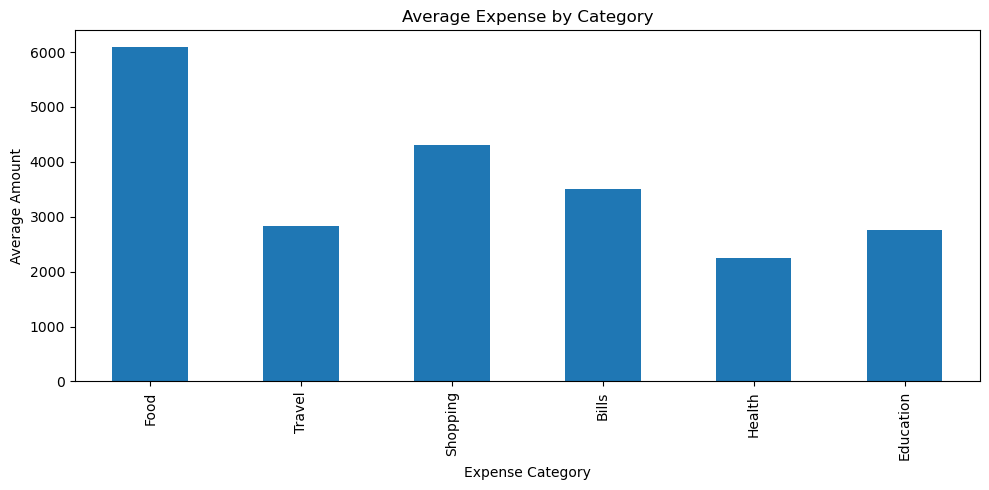

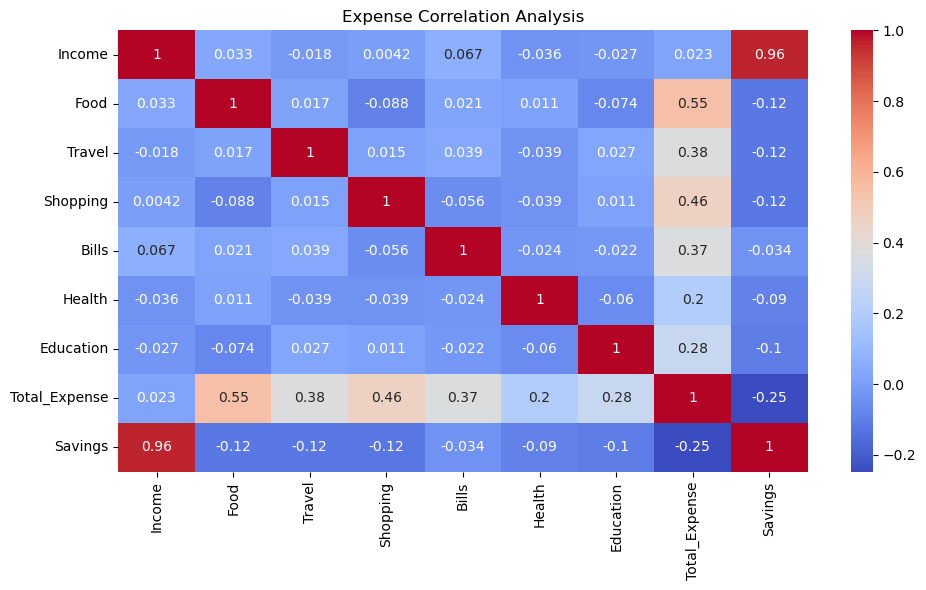


Machine Learning Model Trained Successfully!
MAE: 2052.4771
R2 Score: 0.9637810370022087

Financial Stress Results:
   Income  Total_Expense         Financial_Stress
0   30795          18013  Medium Financial Stress
1   15860          19143    High Financial Stress
2   53158          20458     Low Financial Stress
3   59732          16727     Low Financial Stress
4   26284          25155    High Financial Stress
5   21265          24375    High Financial Stress
6   31850          19637  Medium Financial Stress
7   52194          19322     Low Financial Stress
8   36962          26535  Medium Financial Stress
9   59131          20813     Low Financial Stress

Predicted Savings: ₹ 13497.71

Analyzed CSV Saved Successfully!
ML Model Saved Successfully!

AI EXPENSE ANALYZER COMPLETED
Total Records: 500
CSV File: analyzed_expense_data.csv
ML Model: expense_model.pkl


In [1]:
# ==================================================
# AI-BASED PERSONAL EXPENSE PATTERN ANALYZER
# ==================================================

# 1. Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
print("Libraries Imported Successfully!")
# 2. Read CSV Dataset
df = pd.read_csv("expense_dataset.csv")
print("\nCSV File Read Successfully!")

print("\nFirst 5 Records:")
print(df.head())

print("\nDataset Information:")
print(df.info())


# 3. Data Cleaning

df.columns = df.columns.str.strip()

df = df.drop_duplicates()

df = df.dropna()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nCleaned Dataset:")
print(df.head())


# 4. Check Required Columns

required_columns = [
    'Income', 'Food', 'Travel', 'Shopping',
    'Bills', 'Health', 'Education'
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"CSV मध्ये खालील columns नाहीत: {missing_columns}"
    )


# 5. Convert Data into Numeric Format

for col in required_columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df = df.dropna(subset=required_columns)


# 6. Calculate Total Expenses

expense_columns = [
    'Food', 'Travel', 'Shopping',
    'Bills', 'Health', 'Education'
]

df['Total_Expense'] = df[expense_columns].sum(axis=1)

df['Savings'] = df['Income'] - df['Total_Expense']

print("\nExpense Calculation Completed!")


# 7. Data Analysis

print("\nDataset Statistics:")
print(df.describe())

print("\nTotal Income:", df['Income'].sum())

print("Total Expense:", df['Total_Expense'].sum())

print("Total Savings:", df['Savings'].sum())


# 8. Expense Visualization

average_expenses = df[expense_columns].mean()

plt.figure(figsize=(10, 5))

average_expenses.plot(kind='bar')

plt.title("Average Expense by Category")
plt.xlabel("Expense Category")
plt.ylabel("Average Amount")

plt.tight_layout()
plt.show()


# 9. Correlation Heatmap

plt.figure(figsize=(10, 6))

sns.heatmap(
    df[required_columns + ['Total_Expense', 'Savings']].corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title("Expense Correlation Analysis")
plt.tight_layout()
plt.show()


# 10. Machine Learning Model

X = df[required_columns]

y = df['Savings']

if len(df) < 10:
    raise ValueError(
        "ML training "
    )

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("\nMachine Learning Model Trained Successfully!")

print("MAE:", mean_absolute_error(y_test, predictions))

print("R2 Score:", r2_score(y_test, predictions))


# 11. Financial Stress Analysis

def financial_stress(income, expense):

    if income <= 0:
        return "Invalid Income"

    ratio = (expense / income) * 100

    if ratio < 50:
        return "Low Financial Stress"

    elif ratio < 75:
        return "Medium Financial Stress"

    else:
        return "High Financial Stress"


df['Financial_Stress'] = df.apply(
    lambda row: financial_stress(
        row['Income'],
        row['Total_Expense']),
    axis=1 )

print("\nFinancial Stress Results:")
print(df[['Income', 'Total_Expense', 'Financial_Stress']].head(10))


# 12. Predict New Expenses

new_expense = pd.DataFrame({
    'Income': [30000],
    'Food': [4000],
    'Travel': [2000],
    'Shopping': [3000],
    'Bills': [2500],
    'Health': [1000],
    'Education': [1500]
    })

predicted_savings = model.predict(new_expense)

print("\nPredicted Savings: ₹", round(predicted_savings[0], 2))


# 13. Save Analyzed CSV File

df.to_csv("analyzed_expense_data.csv", index=False)

print("\nAnalyzed CSV Saved Successfully!")


# 14. Save Machine Learning Model

joblib.dump(model, "expense_model.pkl")

print("ML Model Saved Successfully!")


# 15. Final Output

print("\n======================================")
print("AI EXPENSE ANALYZER COMPLETED")
print("======================================")

print("Total Records:", len(df))

print("CSV File: analyzed_expense_data.csv")

print("ML Model: expense_model.pkl")